# Beat 7: Guided Grad-CAM

**Pergunta:** dá para ter resolução **e** discriminação?

O Guided Backprop tem resolução de pixel (224x224) e não sabe de qual classe se
trata: o mapa de "gato" e o de "cachorro" na mesma foto são quase idênticos
(Fase 3). O Grad-CAM sabe de classe, mas entrega 14x14. O Guided Grad-CAM é o
produto dos dois:

$$L^c_{\text{guided}} = \text{Upsample}\left(L^c_{\text{Grad-CAM}}\right) \odot \text{GuidedBackprop}(x)$$

O método está em `gradcam/guided.py`; a bateria completa (4 imagens, medidas de
localização e de detalhe) é `scripts/06_guided_gradcam.py`.


In [1]:
import os
import sys

sys.path.append(os.path.abspath("."))
sys.path.append(os.path.abspath("notebooks"))

import matplotlib.pyplot as plt
import torch

import deck
from gradcam.core import gradcam
from gradcam.data import CocoVal
from gradcam.guided import compose_guided_gradcam, guided_gradcam
from gradcam.models import (
    denormalize, imagenet_labels, load_model, preprocess, resolve_class,
)
from gradcam.saliency import guided_backprop
from gradcam.viz import figure_grid, gray_rgb, tensor_to_numpy, upsample

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
coco = CocoVal()
print(f"vgg16 em {device} | {len(labels)} classes | {len(coco)} imagens do val2017")

vgg16 em cpu | 1000 classes | 5000 imagens do val2017


## O caso do artigo: gato e cachorro na mesma foto

`cat` e `dog` não são classes ImageNet verbatim (a lista tem só 18 categorias
COCO, ver `plans/general_plan.md` seção 0), então o cue é um synset explícito:
`Egyptian cat` e `beagle`. O top-1 do modelo nesta foto é outro animal — o cue
é a classe que **perguntamos**, não a predição.

A coluna `grad-cam` é desenhada na resolução nativa (14x14): é a resolução que
ela tem. As duas últimas colunas são 224x224.

Egyptian cat     biblioteca == composicao: True


beagle           biblioteca == composicao: True


C:\Users\vinicius\Desktop\deep_learning\GradCAM-Study\notebooks\deck.py:21: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


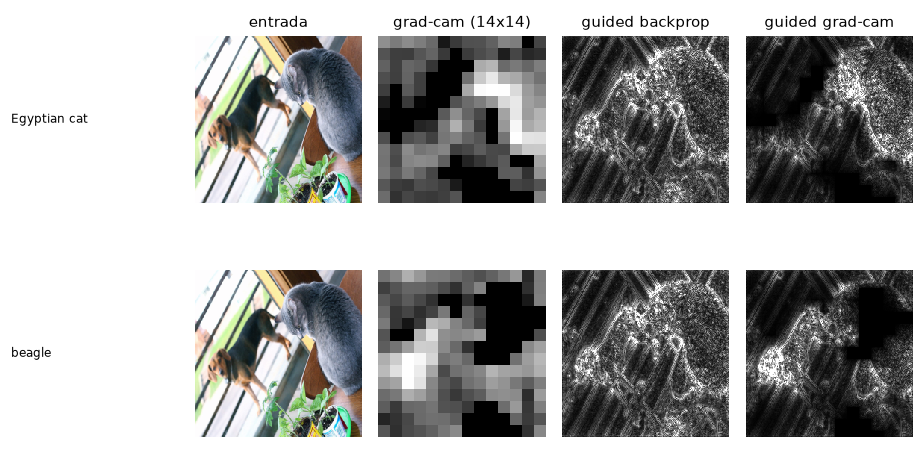

In [2]:
image_id = 22892
cues = ("Egyptian cat", "beagle")

x = preprocess(coco.load_image(image_id))
image_rgb = tensor_to_numpy(denormalize(x))

rows, titles = [], []
for cue in cues:
    class_idx = resolve_class(cue, labels)
    cam, _ = gradcam(model, x, class_idx)
    detail, _ = guided_backprop(model, x, class_idx)
    composed = compose_guided_gradcam(cam, detail, (224, 224))
    library, _ = guided_gradcam(model, x, class_idx)

    # Celula-espelho: a chamada de biblioteca tem que devolver a composicao
    # feita a mao, senao a figura nao e' do metodo que o texto descreve.
    print(f"{cue:16s} biblioteca == composicao: {torch.allclose(library, composed, atol=1e-6)}")

    rows.append([
        image_rgb,
        gray_rgb(cam, high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA),
        gray_rgb(detail, high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA),
        gray_rgb(composed, high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA),
    ])
    titles.append(cue)

fig = figure_grid(
    rows,
    col_titles=("entrada", "grad-cam (14x14)", "guided backprop", "guided grad-cam"),
    row_titles=titles,
    figsize=(8.5, 4.4),
    dpi=110,
)
deck.show(fig)

**O que a figura mostra:** o mapa de `Egyptian cat` acende o gato (à direita) e
o de `beagle` acende o cachorro (à esquerda); o `guided backprop` é praticamente
o mesmo nas duas linhas, porque não depende da classe. O produto herda a
seleção de região do Grad-CAM e a textura do Guided Backprop.

## Zoom: a textura que o CAM não tem

Recorte na região do guarda-chuva (`47585`, cue `umbrella`). O CAM chega liso —
é uma grade de 14x14 interpolada; o Guided Grad-CAM traz as hastes e os setores
do tecido. É a metade "resolução" do critério.

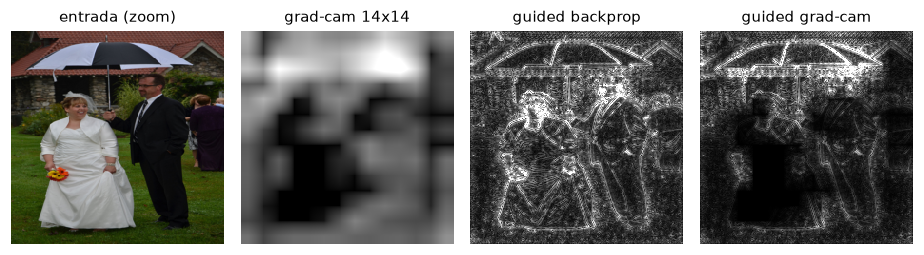

In [3]:
zoom_id, zoom_cue, zoom_object = 47585, "umbrella", "umbrella"

x_zoom = preprocess(coco.load_image(zoom_id))
image_zoom = tensor_to_numpy(denormalize(x_zoom))
class_zoom = resolve_class(zoom_cue, labels)
cam_zoom, _ = gradcam(model, x_zoom, class_zoom)
detail_zoom, _ = guided_backprop(model, x_zoom, class_zoom)
ggc_zoom = compose_guided_gradcam(cam_zoom, detail_zoom, (224, 224))

# A box do COCO e' escalada para a grade de 224: `preprocess` redimensiona sem crop.
meta = coco.images[zoom_id]
sx, sy = 224 / meta["width"], 224 / meta["height"]
box = max(coco.boxes[zoom_id][zoom_object], key=lambda b: b.area())
side = int(min(224, max(64, 1.28 * max(box.w * sx, box.h * sy))))
cx, cy = int((box.x + box.w / 2) * sx), int((box.y + box.h / 2) * sy)
x0 = min(max(0, cx - side // 2), 224 - side)
y0 = min(max(0, cy - side // 2), 224 - side)

def crop(cell):
    return cell[y0:y0 + side, x0:x0 + side]

cells = [
    crop(image_zoom),
    crop(gray_rgb(upsample(cam_zoom, (224, 224)), high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA)),
    crop(gray_rgb(detail_zoom, high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA)),
    crop(gray_rgb(ggc_zoom, high=deck.DISPLAY_HIGH, gamma=deck.DISPLAY_GAMMA)),
]
fig = figure_grid(
    [cells],
    col_titles=("entrada (zoom)", "grad-cam 14x14", "guided backprop", "guided grad-cam"),
    figsize=(8.5, 2.6),
    dpi=110,
)
deck.show(fig)

**Takeaway.** O Guided Grad-CAM soma as duas propriedades, mas não de graça: o
termo de detalhe é quase invariante à classe (rho 0,999 na Fase 3), então a
discriminação fina continua vindo do CAM — no mapa do produto, o que se recupera
é a textura, e a localização só se mantém porque a máscara do CAM é forte.

Os números completos (top-5% dentro da box de ground truth, índice de detalhe,
rho entre classes) saem de `scripts/06_guided_gradcam.py`, e a leitura crítica
está em `plans/general_plan.md`, seção 0, "Medições da etapa 6". Limitação
medida: em fotos em que um objeto domina o gradiente, classe difusa não localiza
nem antes nem depois do produto.

Próximo beat: [08_numeros.ipynb](08_numeros.ipynb) — nossos números contra os do
paper. Anterior: [05_equivalencia.ipynb](05_equivalencia.ipynb).